# Homework 2: Problems (due 7 October 2026 23:59:59)
### PHYS 440/540, Fall 2026


## Problem 1

This question is about IQ. It is questionable whether this is a meaningful metric, but it is useful for this problem. By definition, IQ is calibrated as a Gaussian distribution with $\mu=100$ and $\sigma=15$. 

1) Create a `scipy.stats` Gaussian object with these properties. Plot the distribution, including the results of 10 random draws.

2) Access the `cdf` property of the Gaussian object and plot it over the same $x$-range as in (1) but in a different figure. 

3) Access the `ppf` property (percent point function) and use *inverse transform sampling* of the cdf to draw $10^4$ random samples, and make a histogram of these. Overplot the pdf from (1). These should match.

4) What fraction of people have IQ > 145? *Hint: investigate all the properties of the Gaussian object from (1) to find the relevant property that gives you this, or perform a calculation involving the cdf.*

5) What IQ corresponds to "one in a million"?


## Problem 2
Follow the example from the Central Limit Theorem cells in BasicStats2.ipynb and simulate the distribution of 100,000 draws of a (very) non-Gaussian distribution (for example chi-square with $k=3$).  Demonstrate that the result confirms the central limit theorem by showing that the mean of the draws becomes Gaussian with large `N`.

See below for code starter.


## Problem 3

On Data Camp:

Complete 2 chapters of any of the following:
- [Intro to Statistics in Python](https://app.datacamp.com/learn/courses/introduction-to-statistics-in-python)
- [Statistical Thinking in Python: Part 1](https://app.datacamp.com/learn/courses/statistical-thinking-in-python-part-1)
- [Statistical Thinking in Python: Part 2](https://app.datacamp.com/learn/courses/statistical-thinking-in-python-part-2)

Without knowing your background, I don't want to pick any particular ones of these to assign.  Upload a screenshot as proof that you've done two chapters in any of these (I'm not concerned with what your score is -- just that you've completed it.)

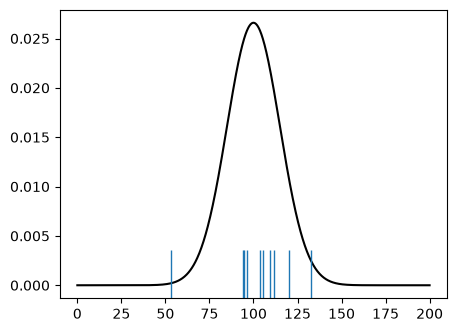

In [1]:
#Problem 1, Part 1 starter code
from scipy import stats
import numpy as np
from scipy.stats import norm
from matplotlib import pyplot as plt
from random import random

mu = 100
sigma = 15

distG = stats.norm(loc=mu, scale=15) # Normal distribution with mean, stdev

xgrid = np.linspace(0,200,1000) # generate distribution for a uniform grid of x values
gaussPDF = distG.pdf(xgrid)  # y values for each x

xrvs = distG.rvs(size=10) # 10 random draws


# actual plotting
fig, ax = plt.subplots(figsize=(5, 3.75))
plt.plot(xgrid, gaussPDF, ls='-', c='black')
plt.plot(xrvs, 0*xrvs, '|', markersize=50)  #Plotting the 10 random draws

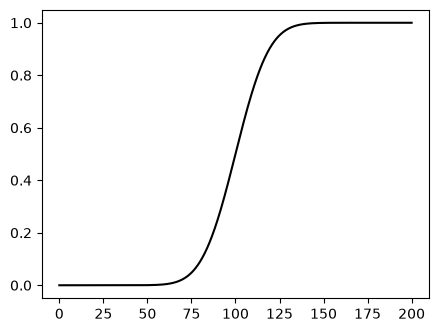

In [2]:
#Problem 1, Part 2 starter code

#The same as above but now with the cdf method
gaussCDF = distG.cdf(xgrid)
fig, ax = plt.subplots(figsize=(5, 3.75))
plt.plot(xgrid, gaussCDF, ls='-', c='black')

(array([0.00134444, 0.        , 0.00134444, 0.00134444, 0.00134444,
        0.00134444, 0.00134444, 0.00268888, 0.00403332, 0.00403332,
        0.00537777, 0.00672221, 0.00806665, 0.01075553, 0.01209997,
        0.01478886, 0.01747774, 0.02151106, 0.02554439, 0.03092215,
        0.03629992, 0.04167769, 0.04974433, 0.05646654, 0.06587763,
        0.07663316, 0.08604425, 0.09814423, 0.11158864, 0.12503306,
        0.13982191, 0.15461077, 0.17074407, 0.18822181, 0.2043551 ,
        0.22317728, 0.24199947, 0.25813276, 0.27695494, 0.29443268,
        0.31056598, 0.32669928, 0.34148813, 0.35493255, 0.36703252,
        0.37644361, 0.3858547 , 0.39257691, 0.39661023, 0.39795468,
        0.39795468, 0.39661023, 0.39257691, 0.3858547 , 0.37644361,
        0.36703252, 0.35493255, 0.34148813, 0.32669928, 0.31056598,
        0.29443268, 0.27695494, 0.25813276, 0.24199947, 0.22317728,
        0.2043551 , 0.18822181, 0.17074407, 0.15461077, 0.13982191,
        0.12503306, 0.11158864, 0.09814423, 0.08

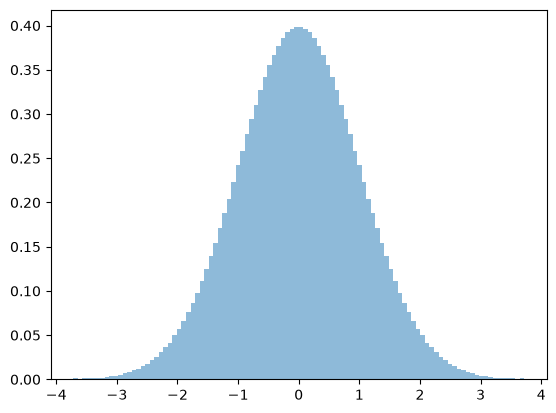

In [4]:
#Problem 1, Part 3 starter code

#These next 2 lines sample the full distribution, but from the opposite direction as Part 1
#(what normal distribution value goes with each probability instead of the other way around)
ppfvals = np.linspace(0.0001,0.9999,10000) #10000 probabilities to sample (from 0.0001 to 0.9999)
results = stats.norm.ppf(ppfvals) #Value of the normal distribution at those probabilities

plt.hist(results,bins=100,histtype='stepfilled', alpha=0.5, density=True)


In [9]:
#Problem 1, Part 4 starter code
#What fraction of people have IQ>140?
#cdf is fraction of people with IQ<=140

sf140 = 1 - distG.cdf(140)
print(sf140)

0.003830380567589775


In [12]:
#Problem 1, Part 5 starter code
#You could do this coming from the left or from the right
#(with the ppf or with another method of `norm`)

OneInAMillionVal = distG.ppf(0.999999)
print('IQ=', OneInAMillionVal)

IQ= 171.3013646322563


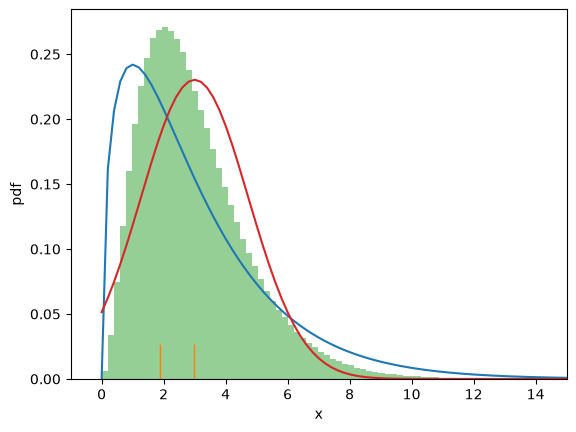

In [14]:
#Problem 2 starter coded
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm, chi2
from scipy import stats

N=2 # Number of draws.  Show both small and large values

xgrid = np.linspace(0,200,1000) # Array to sample the space

dist = chi2(df=3) # try chi-square with 3 degrees of freedom
plt.plot(xgrid, dist.pdf(xgrid)) # Complete

#Rug plot of N random draws
x = dist.rvs(N) # N random draws
plt.plot(x, 0*x, '|', markersize=50) #Rug plot of random draws
plt.xlabel('x')
plt.ylabel('pdf')
plt.xlim(-1,15) #Limit the x-axis range to make things easier to see

# Repeat that 1,000,000 times, averaging the N draws each time
# You could do this any number o ways (including with just 1 line)
yy = []
for i in np.arange(1000000): # Complete
    xx = dist.rvs(N) # N random draws
    yy.append(xx.mean()) # Append average of those random draws to the end of the array

#Plot the histogram with Scott or Freedman bins    
_ = plt.hist(yy,bins=100,density=True,histtype='stepfilled',alpha=0.5)

#Overplot a Gaussian at the appropriate location
#Note that the scale will depend on what function non-gaussian function you choose above.
distG = stats.norm(loc=3,scale=np.sqrt(6/N)) # Complete
plt.plot(xgrid,distG.pdf(xgrid)) # Complete

In [2]:
#Problem 3 
#Upload your screen shots
from IPython import display

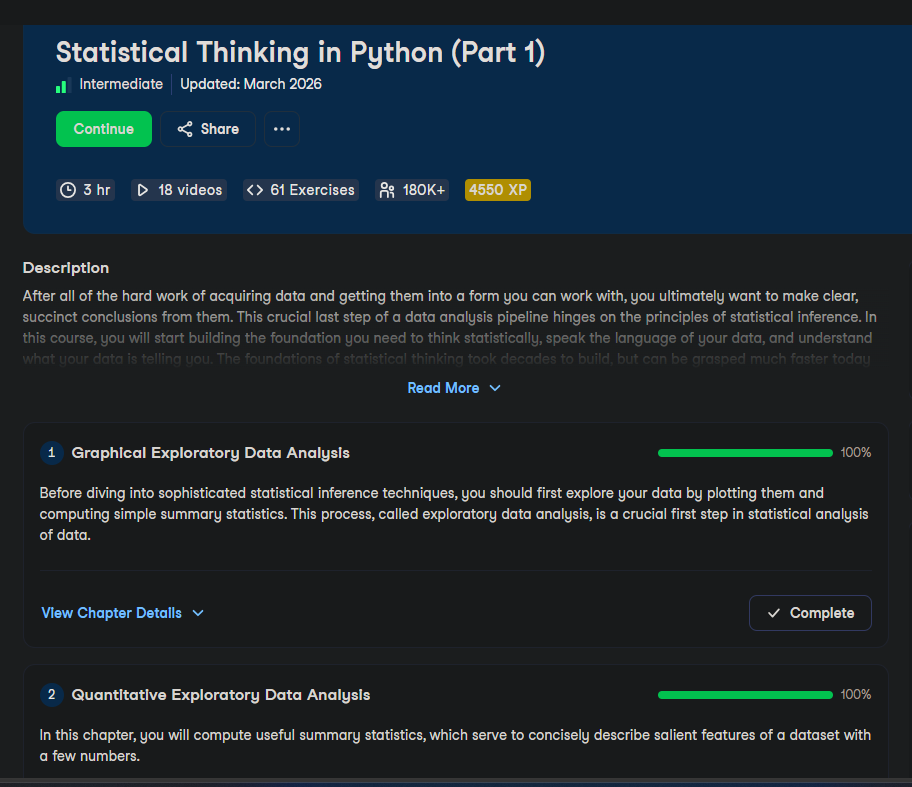

In [3]:
display.Image("h1_datacamp.png")

### Some useful definitions and functions

In [15]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import stats
from astroML.plotting import setup_text_plots
from astroML.stats import sigmaG
from astroML.plotting import hist as fancyhist
setup_text_plots(fontsize=14, usetex=True)
%matplotlib inline

c:\Users\sarda_hx81cfu\AppData\Local\Programs\Python\Python314\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


This astroML function adjusts matplotlib settings for a uniform feel in the 
textbook. Note that with `usetex=True`, fonts are rendered with $\LaTeX$. This 
may result in an error if $\LaTeX$ is not installed on your system.  In that 
case, you can set usetex to `False`.